# 2 · Rolling forecasts

Reads `features` from `data/spx.db`, runs every rolling out-of-sample forecast and writes the results back:

| table | content |
| --- | --- |
| `predictions` | one row per (experiment, model, spec, date): `y_true`, `y_pred`, `state`, `block` |
| `cv_windows` | per refit window: train / validation RMSE (log units) and number of trees |
| `spike_predictions` | spike classifiers: one row per (spec, date) with `y`, `p`, `state` |
| `shap_importance` | mean \|SHAP\| of the last-window XGBoost model |

Each section writes its own experiment as soon as it finishes, so a section can be re-run on its own.

In [1]:
import sqlite3
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import lightgbm as lgb
import shap
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import root_mean_squared_error
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore', message=".*'eval_set' is deprecated.*")   # lightgbm>=4.6 API rename only

In [2]:
# ---- configuration ----
DB_PATH       = '../data/spx.db'
TRAIN_WINDOW  = 500
VAL_WINDOW    = 50
CV_STEP       = 21              # refit monthly, forecast the next 21 days
SEED          = 42

In [3]:
with sqlite3.connect(DB_PATH) as con:
    df = pd.read_sql('select * from features order by date', con, index_col='date', parse_dates=['date'])
df['train_ok'] = df['train_ok'].astype(bool)

model_features = ['log_spread_lag1', 'log_spread_lag2', 'rv_5', 'rv_21', 'price_trend',
                  'log_volume_lag1', 'ami_lag1', 'pe_diff_lag1', 'pandemic_dummy', 'prob_state_1_lag1']
no_hmm = [f for f in model_features if f != 'prob_state_1_lag1']
har_feats = ['har_5', 'har_22', 'har_63']
cal_feats = ['pre_holiday', 'post_holiday', 'month_end', 'month_start', 'opex', 'quad_witching',
             'dow_mon', 'dow_tue', 'dow_wed', 'dow_thu']

df_model = df.dropna(subset=model_features + ['y']).copy()
print("Rows for modelling:", len(df_model), "|", df_model.index.min().date(), "to", df_model.index.max().date())
print("Training-eligible rows (non-outlier):", int(df_model['train_ok'].sum()))

Rows for modelling: 6195 | 2001-03-29 to 2025-11-13
Training-eligible rows (non-outlier): 5744


## Rolling time-series CV

For each refit date *i* (every `CV_STEP` days): history = previous `TRAIN_WINDOW` rows, outliers removed;
the last `VAL_WINDOW` rows are used for early stopping; the model is then refit on train+val with the chosen number of trees
and forecasts rows `[i, i+CV_STEP)`. Models are fitted on `log_y` and forecasts are mapped back with `exp()`.

In [4]:
TREE_PARAMS = dict(max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=SEED)

def make_model(model_type, n_estimators=2000, early_stop=True):
    if model_type == 'xgb':
        return xgb.XGBRegressor(n_estimators=n_estimators, objective='reg:squarederror', eval_metric='rmse',
                                early_stopping_rounds=50 if early_stop else None, verbosity=0, n_jobs=4, **TREE_PARAMS)
    if model_type == 'lgb':
        return lgb.LGBMRegressor(n_estimators=n_estimators, num_leaves=8, subsample_freq=1, objective='regression',
                                 verbose=-1, n_jobs=4, **TREE_PARAMS)
    raise ValueError(model_type)


def rolling_cv(data, features, target='log_y', inverse=np.exp, level_col='y', train_window=TRAIN_WINDOW,
               val_window=VAL_WINDOW, step=CV_STEP, model_type='xgb', mask_col='train_ok'):
    # models are fitted on `target`; forecasts are mapped back with `inverse` and stored on the level scale
    preds, windows = [], []
    last_model = last_X = None
    for i in range(train_window, len(data), step):
        hist = data.iloc[i - train_window:i]
        if mask_col is not None:
            hist = hist[hist[mask_col]]
        train, val, test = hist.iloc[:-val_window], hist.iloc[-val_window:], data.iloc[i:i + step]
        Xtr, ytr = train[features].values, train[target].values
        Xva, yva = val[features].values, val[target].values
        Xte = test[features].values
        Xprod, yprod = np.vstack([Xtr, Xva]), np.concatenate([ytr, yva])
        best_iter, train_rmse, val_rmse = np.nan, np.nan, np.nan

        if model_type in ('xgb', 'lgb'):
            base = make_model(model_type)
            if model_type == 'xgb':
                base.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
                best_iter = base.best_iteration + 1
                val_rmse = base.evals_result()['validation_0']['rmse'][base.best_iteration]
            else:
                base.fit(Xtr, ytr, eval_set=[(Xva, yva)], eval_metric='rmse',
                         callbacks=[lgb.early_stopping(50, verbose=False)])
                best_iter = base.best_iteration_ or base.n_estimators
                val_rmse = base.best_score_['valid_0']['rmse']
            train_rmse = root_mean_squared_error(ytr, base.predict(Xtr))
            prod = make_model(model_type, n_estimators=int(best_iter), early_stop=False).fit(Xprod, yprod)
            y_pred = prod.predict(Xte)
        elif model_type == 'lin':
            scaler = StandardScaler().fit(Xtr)
            base = LinearRegression().fit(scaler.transform(Xtr), ytr)
            train_rmse = root_mean_squared_error(ytr, base.predict(scaler.transform(Xtr)))
            val_rmse = root_mean_squared_error(yva, base.predict(scaler.transform(Xva)))
            scaler = StandardScaler().fit(Xprod)
            prod = LinearRegression().fit(scaler.transform(Xprod), yprod)
            y_pred = prod.predict(scaler.transform(Xte))
        elif model_type == 'persistence':
            prod = None
            y_pred = test['spread_lag1'].values         # already on the level scale
        else:
            raise ValueError("model_type must be 'lin', 'xgb', 'lgb' or 'persistence'")

        if model_type != 'persistence':
            y_pred = inverse(y_pred)
        preds.append(pd.DataFrame({'y_true': test[level_col].values, 'y_pred': y_pred,
                                   'state': test['hmm_state'].values, 'block': i}, index=test.index))
        windows.append({'date': test.index[0], 'train_rmse': train_rmse, 'val_rmse': val_rmse, 'best_iter': best_iter})
        last_model, last_X = prod, hist[features]
    return pd.concat(preds), pd.DataFrame(windows).set_index('date'), (last_model, last_X)


def save_experiment(experiment, runs):
    # runs: {(model, spec): (predictions, windows)} -> replace this experiment's rows in the database
    preds = pd.concat([p.assign(experiment=experiment, model=m, spec=s) for (m, s), (p, _) in runs.items()])
    wins = pd.concat([w.assign(experiment=experiment, model=m, spec=s) for (m, s), (_, w) in runs.items()])
    for t in (preds, wins):
        t.index = t.index.strftime('%Y-%m-%d')
    with sqlite3.connect(DB_PATH) as con:
        for table, data in [('predictions', preds), ('cv_windows', wins)]:
            if con.execute("select 1 from sqlite_master where type='table' and name=?", (table,)).fetchone():
                con.execute(f'delete from {table} where experiment = ?', (experiment,))
            data.to_sql(table, con, if_exists='append', index=True, index_label='date')
    print(f"{experiment}: {len(runs)} runs, {len(preds)} prediction rows saved")

## 2.1 Main comparison

XGBoost, LightGBM, linear regression and persistence on the full feature set, plus the linear model on the level target
(level spread lags) as a reference.

In [5]:
main, last_fit = {}, {}
for name, mt in [('XGBoost', 'xgb'), ('LightGBM', 'lgb'), ('Linear', 'lin'), ('Persistence', 'persistence')]:
    p, w, last_fit[name] = rolling_cv(df_model, model_features, model_type=mt)
    main[(name, 'baseline')] = (p, w)
level_features = ['spread_lag1', 'spread_lag2'] + model_features[2:]
p, w, _ = rolling_cv(df_model, level_features, target='y', inverse=lambda v: v, model_type='lin')
main[('Linear (level y)', 'baseline')] = (p, w)
save_experiment('main', main)

main: 5 runs, 28475 prediction rows saved


## 2.2 SHAP — XGBoost model of the last rolling window

The model that produced the most recent forecasts (not a full-sample in-sample model). Values are in log-spread units.

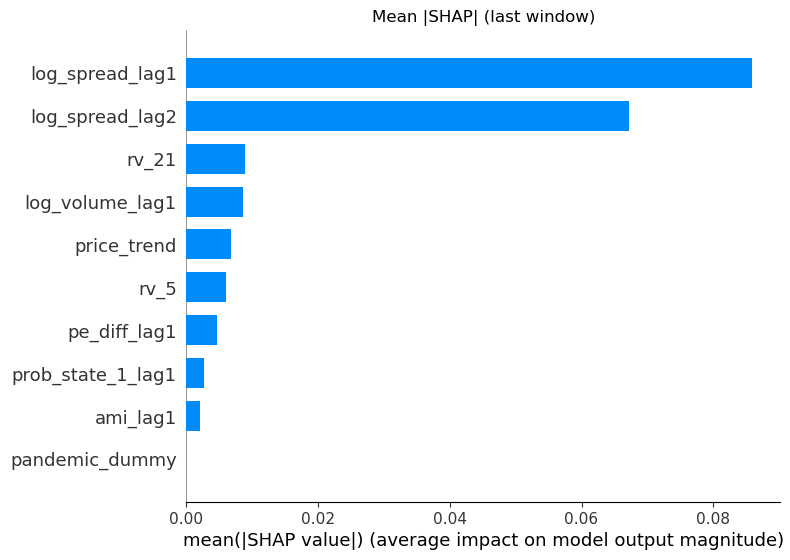

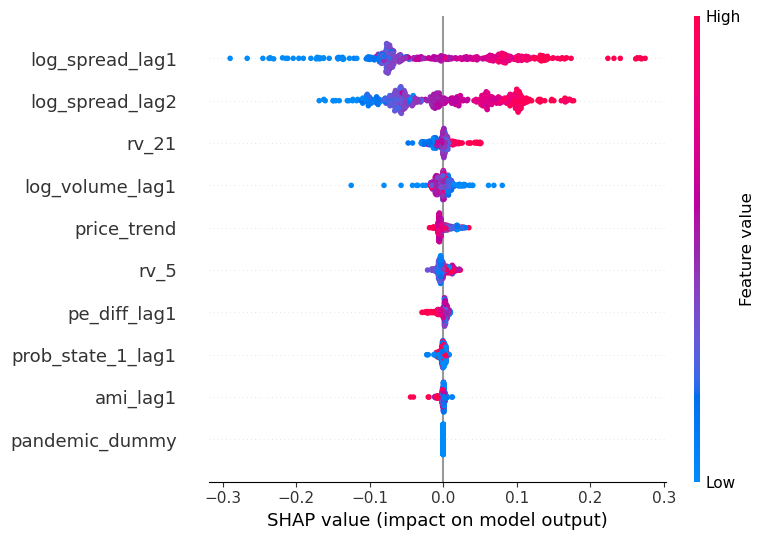

In [6]:
model_last, X_last = last_fit['XGBoost']
X_last = pd.DataFrame(X_last.values, columns=model_features, index=X_last.index)
sv = shap.TreeExplainer(model_last)(X_last)
shap.summary_plot(sv, X_last, plot_type='bar', show=False); plt.title('Mean |SHAP| (last window)'); plt.show()
shap.summary_plot(sv, X_last, show=False); plt.show()

shap_importance = (pd.DataFrame({'feature': model_features, 'mean_abs_shap': np.abs(sv.values).mean(axis=0)})
                   .sort_values('mean_abs_shap', ascending=False))
with sqlite3.connect(DB_PATH) as con:
    shap_importance.to_sql('shap_importance', con, if_exists='replace', index=False)

## 2.3 HMM ablation: the same CV without `prob_state_1_lag1`

In [7]:
ablation = {}
for name, mt in [('XGBoost', 'xgb'), ('LightGBM', 'lgb'), ('Linear', 'lin')]:
    p, w, _ = rolling_cv(df_model, no_hmm, model_type=mt)
    ablation[(name, 'no HMM')] = (p, w)
save_experiment('ablation', ablation)

ablation: 3 runs, 17085 prediction rows saved


## 2.4 HMM variants

Alternative HMM inputs from notebook 1, and regime interactions (`prob_state_1_lag1 ×` the spread lags, a two-step
approximation of a Markov-switching AR model). All specifications use the same rows.

In [8]:
df_model['hmm_x_lag1'] = df_model['prob_state_1_lag1'] * df_model['log_spread_lag1']
df_model['hmm_x_dlag'] = df_model['prob_state_1_lag1'] * (df_model['log_spread_lag1'] - df_model['log_spread_lag2'])
variant_specs = {
    'no HMM':             no_hmm,
    'baseline HMM':       model_features,
    'local-z HMM':        no_hmm + ['hmm_local_z_lag1'],
    'dynamics HMM':       no_hmm + ['hmm_dynamics_lag1'],
    'HMM + interactions': model_features + ['hmm_x_lag1', 'hmm_x_dlag'],
}
df_var = df_model.dropna(subset=['hmm_local_z_lag1', 'hmm_dynamics_lag1'])
variants = {}
for mt, name in [('lin', 'Linear'), ('lgb', 'LightGBM')]:
    for spec, f in variant_specs.items():
        p, w, _ = rolling_cv(df_var, f, model_type=mt)
        variants[(name, spec)] = (p, w)
save_experiment('hmm_variants', variants)

hmm_variants: 10 runs, 56490 prediction rows saved


## 2.5 HAR long-memory and calendar features

In [9]:
ext_specs = {'base': model_features, '+HAR': model_features + har_feats,
             '+calendar': model_features + cal_feats, '+HAR+calendar': model_features + har_feats + cal_feats}
df_ext = df_model.dropna(subset=har_feats)
har_cal = {}
for mt, name in [('lin', 'Linear'), ('lgb', 'LightGBM')]:
    for spec, f in ext_specs.items():
        p, w, _ = rolling_cv(df_ext, f, model_type=mt)
        har_cal[(name, spec)] = (p, w)
save_experiment('har_calendar', har_cal)

har_calendar: 8 runs, 45560 prediction rows saved


## 2.6 Spike classification

Forecast P(spike_t) with information up to t-1; logistic regression and LightGBM, refitted every 21 days on the previous
1,000 days. The naive benchmarks (`spike_lag1`, `dist_to_thr`) need no fitting and are evaluated in notebook 3.

In [10]:
df_clf = df_ext.dropna(subset=['spike', 'spike_lag1', 'dist_to_thr'])
print(f"Spike base rate: {df_clf['spike'].mean():.3f} over {len(df_clf)} days")


def rolling_clf(data, features, model='logit', train_window=1000, step=21):
    out = []
    for i in range(train_window, len(data), step):
        tr, te = data.iloc[i - train_window:i], data.iloc[i:i + step]
        Xtr, ytr, Xte = tr[features].values, tr['spike'].values, te[features].values
        if ytr.sum() < 10:
            p = np.full(len(te), ytr.mean())
        elif model == 'logit':
            sc = StandardScaler().fit(Xtr)
            p = LogisticRegression(max_iter=2000).fit(sc.transform(Xtr), ytr).predict_proba(sc.transform(Xte))[:, 1]
        else:
            clf = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, max_depth=3, num_leaves=8, subsample=0.8,
                                     subsample_freq=1, colsample_bytree=0.8, min_child_samples=30,
                                     random_state=SEED, verbose=-1, n_jobs=4)
            p = clf.fit(Xtr, ytr).predict_proba(Xte)[:, 1]
        out.append(pd.DataFrame({'y': te['spike'].values, 'p': p, 'state': te['hmm_state'].values}, index=te.index))
    return pd.concat(out)


clf_base = no_hmm + ['spike_lag1', 'dist_to_thr']
clf_specs = {
    'logit, no HMM':       ('logit', clf_base),
    'logit, +HMM':         ('logit', clf_base + ['prob_state_1_lag1']),
    'logit, +HMM+HAR+cal': ('logit', clf_base + ['prob_state_1_lag1'] + har_feats + cal_feats),
    'LGB, no HMM':         ('lgb', clf_base),
    'LGB, +HMM':           ('lgb', clf_base + ['prob_state_1_lag1']),
    'LGB, +HMM+HAR+cal':   ('lgb', clf_base + ['prob_state_1_lag1'] + har_feats + cal_feats),
}
spike = pd.concat([rolling_clf(df_clf, f, m).assign(spec=spec) for spec, (m, f) in clf_specs.items()])
spike.index = spike.index.strftime('%Y-%m-%d')
with sqlite3.connect(DB_PATH) as con:
    spike.to_sql('spike_predictions', con, if_exists='replace', index=True, index_label='date')
print(f"spike_predictions: {len(spike)} rows")

Spike base rate: 0.138 over 6195 days


spike_predictions: 31170 rows


In [11]:
with sqlite3.connect(DB_PATH) as con:
    print(pd.read_sql("select experiment, model, spec, count(*) as days from predictions group by 1, 2, 3", con).to_string(index=False))

  experiment            model               spec  days
    ablation         LightGBM             no HMM  5695
    ablation           Linear             no HMM  5695
    ablation          XGBoost             no HMM  5695
har_calendar         LightGBM               +HAR  5695
har_calendar         LightGBM      +HAR+calendar  5695
har_calendar         LightGBM          +calendar  5695
har_calendar         LightGBM               base  5695
har_calendar           Linear               +HAR  5695
har_calendar           Linear      +HAR+calendar  5695
har_calendar           Linear          +calendar  5695
har_calendar           Linear               base  5695
hmm_variants         LightGBM HMM + interactions  5649
hmm_variants         LightGBM       baseline HMM  5649
hmm_variants         LightGBM       dynamics HMM  5649
hmm_variants         LightGBM        local-z HMM  5649
hmm_variants         LightGBM             no HMM  5649
hmm_variants           Linear HMM + interactions  5649
hmm_varian